# 01 · Exploration des données

On veut prédire `TotalKg`, le total des trois mouvements en kg, à partir des informations d'une participation à une compétition. La métrique est la RMSE. Il y a 105 000 lignes d'apprentissage, 45 000 de test, 3 variables numériques (âge, poids, année) et 13 catégorielles.

Ce notebook vérifie les fichiers, regarde les données et fixe les cinq plis utilisés partout ensuite. Il tourne sur CPU.

| Notebook | Contenu |
|---|---|
| **01_data_exploration** | lecture des données, exploration, plis |
| **02_feature_engineering** | quatre séries de variables et leurs ablations (exp. 07, 09, 10, 14) |
| **03_model_selection** | modèles, cibles, hyperparamètres, façons de combiner (exp. 08, 13) |
| **04_final_model** | ensemble final, corrections, lissage par paires, soumissions (exp. 11, 12, 15–17) |
| **05_error_analysis** | résidus, essais abandonnés, score local et score public |

Les CSV sont dans `data/`, les résultats dans `artifacts/`. Les numéros d'expérience (07 à 17) sont ceux de notre journal de travail.

In [1]:
"""Compatibilité avec les résultats existants et libellés de présentation.

Les valeurs historiques ci-dessous sont volontairement conservées : elles déterminent
les clés JSON, les noms de caches et leur ordre. Le code de calcul utilise les noms
explicites des constantes ; seules des copies destinées à l’affichage sont traduites.
"""

BLOCK_RECORDING_PRECISION = 'P'
BLOCK_TRAVEL = 'T'
BLOCK_MEET_CONTEXT = 'M'
BLOCK_EXTENDED_MEET_CONTEXT = 'M2'
BLOCK_DIVISION_CONTEXT = 'D'
BLOCK_ATHLETE_HISTORY = 'H'
BLOCK_DOTS_SCALE = 'S'
BLOCK_PROXY_IDENTIFIERS = 'C'
BLOCK_ATHLETE_CAREER = 'H2'
BLOCK_MEET_EXPERIENCE = 'E'
BLOCK_MODEL_SPECIFIC = 'PM'
BLOCK_ATHLETE_PERFORMANCE = 'AS'
BLOCK_MEET_PERFORMANCE = 'MS'
VARIANT_WEIGHT_CLASS_BASELINE = 'F0'
VARIANT_PRECISION_AND_TRAVEL = 'PT'
VARIANT_CONTEXT_COMBINED = 'ALL'
VARIANT_CONTEXT_BASELINE = 'R1'
VARIANT_HISTORY_COMBINED = 'ALL2'
VARIANT_HISTORY_BASELINE = 'R2'
VARIANT_FINAL_FEATURES = 'ALL3'
VARIANT_FINAL_BASELINE = 'R3'
VARIANT_PERFORMANCE_COMBINED = 'ALL4'
CATBOOST_DEPTH8_BASELINE = 'C1'
CATBOOST_DEPTH8_REGULARIZED = 'C2'
CATBOOST_DEPTH6_REGULARIZED = 'C3'
MODEL_LIGHTGBM = 'lgb'
MODEL_XGBOOST = 'xgb'
MODEL_CATBOOST_ABSOLUTE = 'catboost'
MODEL_LIGHTGBM_DOTS = 'lgb_rel'
MODEL_CATBOOST_DOTS = 'cb_rel'
MODEL_CATBOOST_IPF_GL = 'cb_gl'
MODEL_CATBOOST_ALLOMETRIC = 'cb_allo'
MODEL_HISTOGRAM_GRADIENT_BOOSTING = 'hgb'
MODEL_EXTRA_TREES = 'et'
MODEL_RANDOM_FOREST = 'rf'
MATCH_RESIDENCE = 'A0'
MATCH_FEDERATION = 'A1'
MATCH_EQUIPMENT = 'A2'
MATCH_WEIGHT_CLASS = 'A3'
MATCH_MEET = 'M2'
SMOOTHING_EXACT_BIRTHYEAR = 'S0_exact'
SMOOTHING_NEARBY_BIRTHYEAR = 'S1_fuzzy'
SMOOTHING_TEMPORAL = 'S2_decay'
SMOOTHING_COMBINED_LINEAR = 'S3_all_linear'
SMOOTHING_COMBINED_BOOSTING = 'S4_all_gbm'
CACHE_CONTEXT_ABLATION = 'round1'
CACHE_HISTORY_ABLATION = 'round2'
CACHE_CAREER_ABLATION = 'round3'
CACHE_PERFORMANCE_ABLATION = 'round4'
CACHE_SIX_MODEL_ENSEMBLE = 'v1_six_models'
CACHE_EXPANDED_SEED_ENSEMBLE = 'v2_more_seeds'
CACHE_FINAL_ENSEMBLE = 'v4_eight_models'
CACHE_INITIAL_ENSEMBLE = 'baseline_v1'
CACHE_TEN_FOLD_ENSEMBLE = 'baseline_v2'
ENSEMBLE_INITIAL = 'v1'
ENSEMBLE_TEN_FOLD = 'v2'
ENSEMBLE_WITH_HISTOGRAM_BOOSTING = 'v3_plus'
ENSEMBLE_FINAL = 'v4'
MODEL_CATBOOST_DEPTH8_BASELINE = 'catboost_C1'
CONFIG_PURPOSE_CONTEXT_ABLATION = 'feature round 1 (P/T/M blocks); inner 10% early stop, score early-stopped model on outer fold'
CONFIG_PURPOSE_HISTORY_ABLATION = 'feature round 2 on top of 07 ALL; inner 10% early stop, score early-stopped model on outer fold'
CONFIG_PURPOSE_CAREER_ABLATION = 'feature round 3 on top of 09 ALL2; inner 10% early stop, score early-stopped model on outer fold'
MODEL_CATBOOST_DEPTH8_REGULARIZED = 'catboost_C2'
MODEL_CATBOOST_DEPTH6_REGULARIZED = 'catboost_C3'
CONFIG_PURPOSE_MODEL_COMPARISON = 'model zoo on the 07 folds; inner 10% early stop (same split as 07); score on outer fold'

CACHE_CATBOOST_IPF_GL_BASELINE_STEM = 'cb_gl__R3'
CACHE_CATBOOST_IPF_GL_SEED42_STEM = 'cb_gl__s42'
MODEL_CATBOOST_PREFIX = 'cb_'
MODEL_CATBOOST_DOTS_SLOW_LEARNING_RATE = 'cb_rel_lr03'
CONFIG_PURPOSE_SIX_MODEL_ENSEMBLE = 'final ensemble: ALL3 per-model features, 5-fold x seeds, inner 10% early stop, full refit'
SUMMARY_RESIDUAL_SMOOTHING = '+S3'
SUMMARY_FINAL_SMOOTHING = '+ S3 smoothing (cross-fitted coefficients)'
SUMMARY_FINAL_CANDIDATES = '+ HGB + cb_gl (final)'
SUBMISSION_FINAL_BASE_FILENAME = 'submission_final_v4_base.csv'
SUBMISSION_FINAL_FILENAME = 'submission_final_v4_final.csv'

LEGACY_SUMMARY_COMBINED_SMOOTHING = '+ S3 \u5e73\u6ed1\uff08\u4ea4\u53c9\u62df\u5408\uff09'
HISTORY_TEN_FOLD_MATCHING = 'v2 + twins'
HISTORY_WEIGHT_CLASS_MATCHING = '07 F0 + twins'
HISTORY_CONTEXT_REGULARIZED = '07 ALL + C2'
HISTORY_CONTEXT_REGULARIZED_MATCHING = '07 ALL + C2 + twins'
HISTORY_MODEL_STACKING = '08 stack'
HISTORY_STACKING_MATCHING = '08 + twins'
HISTORY_STACKING_RESIDUAL_SMOOTHING = '08 + twins + athlete'
HISTORY_TEN_FOLD_RESIDUAL_SMOOTHING = 'v2 + twins + athlete'
HISTORY_FINAL_FEATURES_MATCHING = '10 ALL3 + twins'
HISTORY_EXACT_BIRTHYEAR_SMOOTHING = '10 + S0'
HISTORY_COMBINED_RESIDUAL_SMOOTHING = '10 + S3'
HISTORY_SIX_MODEL_FOLD_AVERAGE = '11 fold average'
HISTORY_HISTOGRAM_BOOSTING_ENSEMBLE = '13 v3_plus'
HISTORY_FINAL_FEATURES_REFERENCE = '14 R3'
HISTORY_ATHLETE_PERFORMANCE = '14 AS'
HISTORY_FINAL_ENSEMBLE = '15 v4 (final)'


PRESENTATION_LABELS = {
    HISTORY_TEN_FOLD_MATCHING: 'v2 + jumelles',
    HISTORY_WEIGHT_CLASS_MATCHING: 'variables de départ + jumelles',
    HISTORY_CONTEXT_REGULARIZED: 'série 1 + CatBoost régularisé',
    HISTORY_CONTEXT_REGULARIZED_MATCHING: 'série 1 + CatBoost régularisé + jumelles',
    HISTORY_MODEL_STACKING: 'exp. 08 : plus de modèles',
    HISTORY_STACKING_MATCHING: 'exp. 08 + jumelles',
    HISTORY_STACKING_RESIDUAL_SMOOTHING: 'exp. 08 + jumelles + lissage',
    HISTORY_TEN_FOLD_RESIDUAL_SMOOTHING: 'v2 + jumelles + lissage',
    HISTORY_FINAL_FEATURES_MATCHING: 'série 3 + jumelles',
    HISTORY_EXACT_BIRTHYEAR_SMOOTHING: 'série 3 + lissage (même année)',
    HISTORY_COMBINED_RESIDUAL_SMOOTHING: 'série 3 + lissage combiné',
    HISTORY_SIX_MODEL_FOLD_AVERAGE: 'six modèles, moyenne des plis',
    HISTORY_HISTOGRAM_BOOSTING_ENSEMBLE: 'six modèles + HGB',
    HISTORY_FINAL_FEATURES_REFERENCE: 'référence de la série 4',
    HISTORY_ATHLETE_PERFORMANCE: 'niveau du sportif',
    HISTORY_FINAL_ENSEMBLE: 'huit modèles',
    '+ HGB + cb_gl (final, exp. 15)': '+ HGB + CatBoost IPF GL (exp. 15)',
    BLOCK_RECORDING_PRECISION: 'Précision',
    BLOCK_TRAVEL: 'Déplacements',
    BLOCK_MEET_CONTEXT: 'Contexte',
    BLOCK_EXTENDED_MEET_CONTEXT: 'Contexte enrichi',
    BLOCK_DIVISION_CONTEXT: 'Divisions',
    BLOCK_ATHLETE_HISTORY: 'Historique',
    BLOCK_DOTS_SCALE: 'Coefficient DOTS',
    BLOCK_PROXY_IDENTIFIERS: 'Identifiants',
    BLOCK_ATHLETE_CAREER: 'Carrière',
    BLOCK_MEET_EXPERIENCE: 'Expérience du plateau',
    BLOCK_MODEL_SPECIFIC: 'Ajouts par modèle',
    BLOCK_ATHLETE_PERFORMANCE: 'Niveau du sportif',
    BLOCK_MEET_PERFORMANCE: 'Niveau de la compétition',
    VARIANT_WEIGHT_CLASS_BASELINE: 'Départ',
    VARIANT_PRECISION_AND_TRAVEL: 'Précision + déplacements',
    VARIANT_CONTEXT_COMBINED: 'Série 1 complète',
    VARIANT_CONTEXT_BASELINE: 'Référence série 2',
    VARIANT_HISTORY_COMBINED: 'Série 2 retenue',
    VARIANT_HISTORY_BASELINE: 'Référence série 3',
    VARIANT_FINAL_FEATURES: 'Variables finales',
    VARIANT_FINAL_BASELINE: 'Référence série 4',
    VARIANT_PERFORMANCE_COMBINED: 'Niveaux combinés',
    CATBOOST_DEPTH8_BASELINE: 'prof. 8, L2 3',
    CATBOOST_DEPTH8_REGULARIZED: 'prof. 8, L2 10',
    CATBOOST_DEPTH6_REGULARIZED: 'prof. 6, L2 10',
    MODEL_CATBOOST_DOTS: 'CatBoost DOTS',
    MODEL_LIGHTGBM_DOTS: 'LightGBM DOTS',
    MODEL_CATBOOST_IPF_GL: 'CatBoost IPF GL',
    MODEL_CATBOOST_ALLOMETRIC: 'CatBoost allométrique',
    MODEL_LIGHTGBM: 'LightGBM',
    MODEL_XGBOOST: 'XGBoost',
    MODEL_CATBOOST_ABSOLUTE: 'CatBoost',
    MODEL_HISTOGRAM_GRADIENT_BOOSTING: 'HGB',
    MODEL_EXTRA_TREES: 'ExtraTrees',
    MODEL_RANDOM_FOREST: 'Forêt aléatoire',
    MATCH_RESIDENCE: 'Clé 1 :',
    MATCH_FEDERATION: 'Clé 2 :',
    MATCH_EQUIPMENT: 'Clé 3 :',
    MATCH_WEIGHT_CLASS: 'Clé 4 :',
    'S0': 'même année',
    'S1': 'année ±1',
    'S2': 'pondération temporelle',
    'S3': 'lissage combiné',
    'S4': 'lissage LightGBM',
    ENSEMBLE_INITIAL: 'v1',
    ENSEMBLE_TEN_FOLD: 'v2',
    ENSEMBLE_WITH_HISTOGRAM_BOOSTING: 'six modèles + HGB',
    ENSEMBLE_FINAL: 'huit modèles',
    SMOOTHING_EXACT_BIRTHYEAR: 'Même année',
    SMOOTHING_NEARBY_BIRTHYEAR: 'Année ±1',
    SMOOTHING_TEMPORAL: 'Pondération temporelle',
    SMOOTHING_COMBINED_LINEAR: 'Combinaison linéaire',
    SMOOTHING_COMBINED_BOOSTING: 'Combinaison par LightGBM',
}


def presentation_label(value):
    """Traduire un libellé d’expérience sans toucher à sa valeur de calcul."""
    if isinstance(value, tuple):
        return tuple(presentation_label(part) for part in value)
    if not isinstance(value, str):
        return value
    if '|' in value:
        return value
    if value in PRESENTATION_LABELS:
        return PRESENTATION_LABELS[value]
    import re
    if value.endswith(('.csv', '.npz', '.npy', '.json')):
        return value
    keys = [key for key in PRESENTATION_LABELS if key not in (MODEL_EXTRA_TREES, MODEL_RANDOM_FOREST)]
    pattern = r'(?<![A-Za-z0-9_])(' + '|'.join(re.escape(key) for key in sorted(keys, key=len, reverse=True)) + r')(?![A-Za-z0-9_])'
    return re.sub(pattern, lambda match: PRESENTATION_LABELS[match.group()], value)


def presentation_copy(value):
    """Traduire uniquement les libellés de synthèse, sur une copie du tableau."""
    if 'pd' in globals() and isinstance(value, (pd.DataFrame, pd.Series)):
        shown = value.copy(deep=True)
        raw_columns = set(globals().get('RAW_FEATURES', []))
        label_fields = {'model', 'variant', 'tag', 'step', 'method', 'submission',
                        'params_key', 'feature', 'source', 'experiment', 'config',
                        'Ensemble', 'Modèle', 'Expérience', 'Clé'}
        # Un extrait des données conserve toutes ses valeurs et ses catégories.
        if isinstance(shown, pd.DataFrame) and raw_columns.intersection(shown.columns):
            return shown
        if isinstance(shown.index, pd.MultiIndex):
            names = shown.index.names
            shown.index = pd.MultiIndex.from_tuples(
                [tuple(presentation_label(part) if name in label_fields else part
                       for name, part in zip(names, row)) for row in shown.index], names=names)
        elif shown.index.name in label_fields:
            shown.index = shown.index.map(presentation_label)
        if isinstance(shown, pd.DataFrame):
            for column in shown.select_dtypes(include=['object', 'string']):
                if column in label_fields:
                    shown[column] = shown[column].map(presentation_label)
            # Les colonnes de modèles ou de variantes proviennent d’un pivot nommé.
            if shown.columns.name in label_fields:
                shown.columns = shown.columns.map(presentation_label)
        elif shown.name in label_fields and (shown.dtype == object or isinstance(shown.dtype, pd.StringDtype)):
            shown = shown.map(presentation_label)
        return shown
    if isinstance(value, dict):
        return {presentation_label(key): presentation_copy(item) for key, item in value.items()}
    if isinstance(value, list):
        return [presentation_copy(item) for item in value]
    if isinstance(value, tuple):
        return tuple(presentation_copy(item) for item in value)
    return presentation_label(value)


def display(*values, **kwargs):
    """Afficher des libellés explicites sans modifier les tableaux de calcul."""
    return _display(*(presentation_copy(value) for value in values), **kwargs)


def print(*values, **kwargs):
    """Présenter les résumés textuels sans modifier les objets de calcul."""
    import builtins
    return builtins.print(*(presentation_copy(value) for value in values), **kwargs)

In [2]:
# Environnement, chemins et configuration communs aux cinq notebooks
from pathlib import Path
from datetime import datetime, timezone
import gc
import hashlib
import importlib
import importlib.metadata
import inspect
import json
import os
import platform
import shutil
import subprocess
import sys
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display as _display
from scipy.optimize import nnls
from sklearn.model_selection import KFold, train_test_split

try:
    from google.colab import drive
except ModuleNotFoundError:
    drive = None
if drive is not None:
    drive.mount('/content/drive')


def find_project_dir():
    candidates = []
    if os.environ.get('PL_PROJECT_DIR'):
        candidates.append(Path(os.environ['PL_PROJECT_DIR']))
    here = Path.cwd().resolve()
    candidates += [here, *here.parents]
    candidates.append(Path('/content/drive/MyDrive/Colab Notebooks/performances-en-powerlifting'))
    for candidate in candidates:
        if (candidate / 'data' / 'train.csv').is_file() and (candidate / 'data' / 'test.csv').is_file():
            return candidate.expanduser().resolve()
    raise FileNotFoundError('Projet introuvable (data/train.csv et data/test.csv requis) ; définir PL_PROJECT_DIR')


PROJECT_DIR = find_project_dir()
DATA_DIR = PROJECT_DIR / 'data'                 # CSV sources, en lecture seule
ARTIFACTS = PROJECT_DIR / 'artifacts'           # Un sous-dossier de résultats par notebook
SEED = 42                                       # Cinq plis fixes : KFold(5, shuffle=True, random_state=42)
N_FOLDS = 5
INNER_STOP_FRACTION = 0.10                      # 10 % du train externe réservé à l’early stopping
MAX_ROUNDS = 20000
MODELS = [MODEL_LIGHTGBM, MODEL_XGBOOST, MODEL_CATBOOST_ABSOLUTE]             # Trois modèles pour les ablations, les plus rapides en premier
RUN_ONLY = None                                 # Liste de variantes à exécuter ; None = toutes
KEEP_DELTA = -0.05                              # kg : garder si ΔRMSE moyen ≤ −0.05 et amélioration sur ≥ 4/5 plis
EXPECTED_SHA256 = {'train.csv': '62319814116506fb95a51f1185dbacdb170ab055642ee4c347a30584093d0856',
                   'test.csv': '563c6fa29f9e535740ef1f09b25954f00fbe242c81c0e5a7343dc18aa962ba46'}
CATBOOST_VERSION = '1.2.10'
GPU_NAME = None
VERSIONS = {'numpy': np.__version__, 'pandas': pd.__version__, 'python': sys.version.split()[0]}
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})

TRAIN = globals().get('TRAIN', {})              # Pas de bouton dans 01/05 ; 01 entraîne un petit HGB adversarial
if sum(bool(v) for v in TRAIN.values()) > 1:
    raise ValueError('Activer un seul entraînement à la fois ; redémarrer le runtime avant le suivant (variables partagées)')
TRAINING = any(TRAIN.values())


def ensure_training_env():
    """Préparer les dépendances et vérifier le GPU uniquement pour un entraînement."""
    global catboost, lgb, xgb, torch, RealMLP_TD_Regressor, TabM_D_Regressor, PYTABKIT_ERROR, GPU_NAME, VERSIONS
    to_install = []
    try:
        installed_catboost = importlib.metadata.version(MODEL_CATBOOST_ABSOLUTE)
    except importlib.metadata.PackageNotFoundError:
        installed_catboost = None
    if installed_catboost != CATBOOST_VERSION:
        if MODEL_CATBOOST_ABSOLUTE in sys.modules:
            raise RuntimeError('Une autre version de CatBoost est déjà importée ; redémarrer le runtime')
        to_install.append(f'catboost=={CATBOOST_VERSION}')
    try:
        importlib.metadata.version('pytabkit')
    except importlib.metadata.PackageNotFoundError:
        to_install.append('pytabkit')
    if to_install:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *to_install])
        importlib.invalidate_caches()
    import catboost
    import lightgbm as lgb
    import torch
    import xgboost as xgb
    try:
        from pytabkit import RealMLP_TD_Regressor, TabM_D_Regressor
        PYTABKIT_ERROR = None
    except Exception as exc:                    # Les autres modèles restent disponibles si cet import échoue
        RealMLP_TD_Regressor = TabM_D_Regressor = None
        PYTABKIT_ERROR = repr(exc)
    warnings.filterwarnings('ignore', category=UserWarning)
    if catboost.__version__ != CATBOOST_VERSION:
        raise RuntimeError(f'CatBoost {CATBOOST_VERSION} requis ; version actuelle : {catboost.__version__}')
    if shutil.which('nvidia-smi') is None or not torch.cuda.is_available():
        raise RuntimeError('Un GPU est requis : choisir T4 GPU dans le type de runtime Colab, puis relancer')
    GPU_NAME = subprocess.run(['nvidia-smi', '--query-gpu=name,memory.total', '--format=csv,noheader'],
                              text=True, capture_output=True, check=False).stdout.strip().splitlines()[0]
    VERSIONS = {MODEL_CATBOOST_ABSOLUTE: catboost.__version__, 'xgboost': xgb.__version__, 'lightgbm': lgb.__version__,
                'torch': torch.__version__,
                'pytabkit': None if PYTABKIT_ERROR else importlib.metadata.version('pytabkit'),
                'numpy': np.__version__, 'pandas': pd.__version__, 'python': sys.version.split()[0]}
    print('GPU         :', GPU_NAME)
    print('Versions    :', VERSIONS)
    if PYTABKIT_ERROR:
        print('pytabkit indisponible, RealMLP / TabM seront ignorés :', PYTABKIT_ERROR)


print('Projet :', PROJECT_DIR.name)
print(f'Python {platform.python_version()} | pandas {pd.__version__} | numpy {np.__version__}')
if TRAINING:
    print('Entraînements activés :', [k for k, v in TRAIN.items() if v])

Projet : performances-en-powerlifting
Python 3.13.5 | pandas 2.2.3 | numpy 2.1.3


## 1. Lecture et contrôles

Vérification des fichiers (empreinte, dimensions, colonnes, valeurs manquantes) et construction des cinq plis `FOLD_IDS`. Les autres notebooks commencent par la même cellule.

In [3]:
def require(condition, message):
    if not bool(condition):
        raise ValueError(message)


def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()


def rmse(a, b):
    a, b = np.asarray(a, dtype='float64'), np.asarray(b, dtype='float64')
    return float(np.sqrt(np.mean((a - b) ** 2)))


for name, expected in EXPECTED_SHA256.items():
    require(sha256_file(DATA_DIR / name) == expected, f'data/{name} differs from the original input; check the data file')

TARGET = 'TotalKg'
train = pd.read_csv(DATA_DIR / 'train.csv')
test = pd.read_csv(DATA_DIR / 'test.csv')
RAW_NUM = ['Age', 'BodyweightKg', 'MeetYear']
RAW_FEATURES = [c for c in test.columns if c != 'id']
CAT = [c for c in RAW_FEATURES if c not in RAW_NUM]          # Independent of object / str dtype (pandas 2 and 3).
require(train.shape == (105000, 18) and test.shape == (45000, 17), 'Unexpected data shape')
require(len(CAT) == 13 and all(pd.api.types.is_numeric_dtype(train[c]) for c in RAW_NUM)
        and not any(pd.api.types.is_numeric_dtype(train[c]) for c in CAT), 'Unexpected column groups')
require(not train[RAW_FEATURES].isna().any().any() and not test[RAW_FEATURES].isna().any().any(), 'Unexpected missing values')
y = train[TARGET].to_numpy(dtype='float64')
n_train = len(train)

FOLD_IDS = np.zeros(n_train, dtype=int)
for k, (_, valid) in enumerate(KFold(N_FOLDS, shuffle=True, random_state=SEED).split(np.arange(n_train)), start=1):
    FOLD_IDS[valid] = k
print(f'train {train.shape}  test {test.shape}; validation rows per fold: {np.bincount(FOLD_IDS)[1:].tolist()}')

train (105000, 18)  test (45000, 17); validation rows per fold: [21000, 21000, 21000, 21000, 21000]


## 2. Variables

Il n'y a pas de cellule vide : les valeurs inconnues sont codées `Unknown`, surtout pour l'État de résidence, l'État de compétition et la fédération parente.

In [4]:
sample_submission = pd.read_csv(DATA_DIR / 'sample_submission.csv')
require(sample_submission.columns.tolist() == ['id', TARGET] and len(sample_submission) == len(test)
        and set(sample_submission['id']) == set(test['id']), 'Le modèle de soumission ne correspond pas au test')
both_raw = pd.concat([train[RAW_FEATURES], test[RAW_FEATURES]], ignore_index=True)
overview = pd.DataFrame({
    'Type': ['Numérique' if c in RAW_NUM else 'Catégorielle' for c in RAW_FEATURES],
    'Valeurs distinctes (train+test)': [int(both_raw[c].nunique()) for c in RAW_FEATURES],
    'Valeur la plus fréquente': [str(both_raw[c].value_counts().index[0]) for c in RAW_FEATURES],
    'Fréquence du mode': [float(both_raw[c].value_counts(normalize=True).iloc[0]) for c in RAW_FEATURES],
    'Proportion Unknown': [float((both_raw[c].astype(str) == 'Unknown').mean()) for c in RAW_FEATURES],
}, index=RAW_FEATURES)
display(overview.round(3))
display(train[RAW_NUM + [TARGET]].describe().T.round(2))
print('Modèle de soumission :', sample_submission.shape, ', colonnes', sample_submission.columns.tolist())

,Type,Valeurs distinctes (train+test),Valeur la plus fréquente,Fréquence du mode,Proportion Unknown
Age,Numérique,172,17.5,0.035,0.000
BodyweightKg,Numérique,8302,82.5,0.009,0.000
MeetYear,Numérique,62,2024,0.094,0.000
Sex,Catégorielle,3,M,0.691,0.000
Equipment,Catégorielle,5,Raw,0.621,0.000
AgeClass,Catégorielle,19,24-34,0.322,0.000
BirthYearClass,Catégorielle,8,24-39,0.392,0.030
WeightClassKg,Catégorielle,153,90,0.078,0.010
Tested,Catégorielle,2,Yes,0.762,0.000
Country,Catégorielle,152,USA,0.460,0.018


,count,mean,std,min,25%,50%,75%,max
Age,105000.0,28.54,12.06,0.5,19.50,25.0,34.0,92.50
BodyweightKg,105000.0,83.42,21.98,19.1,67.09,81.4,97.1,241.80
MeetYear,105000.0,2017.67,8.01,1966.0,2015.00,2019.0,2023.0,2026.00
TotalKg,105000.0,493.01,171.40,24.0,352.50,492.5,612.5,1363.05


Modèle de soumission : (45000, 2) , colonnes ['id', 'TotalKg']


## 3. La cible

Les distributions sont très différentes entre hommes et femmes. Le poids corporel explique une partie du total, mais deux athlètes de même poids peuvent avoir plusieurs centaines de kilos d'écart. Le niveau de chacun n'est pas dans les variables : c'est ce qui limite la précision, et la RMSE finale reste autour de 76 kg.

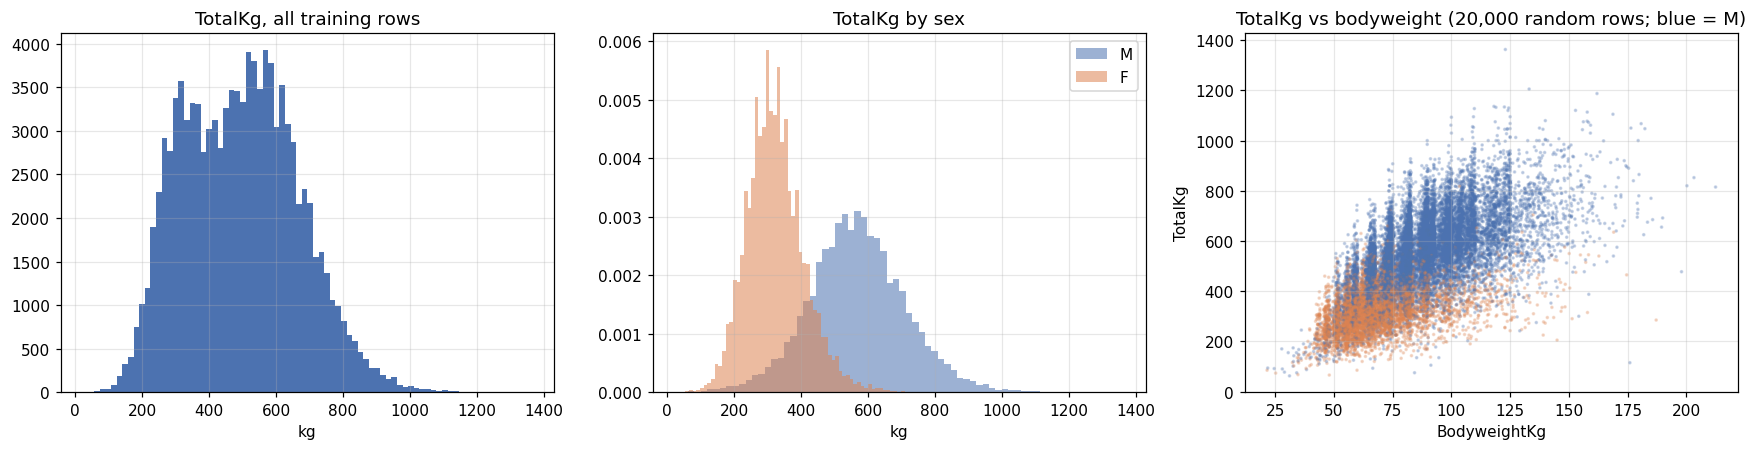

size   mean    std
Sex Equipment                      
F   Multi-ply     380  416.3  126.7
    Raw         21755  314.3   76.1
    Single-ply   6366  342.9  100.0
    Unlimited     521  333.2   85.0
    Wraps        3515  331.3   87.2
M   Multi-ply    2053  716.1  191.7
    Raw         43471  547.1  126.3
    Single-ply  17352  592.7  160.2
    Unlimited     545  569.3  162.3
    Wraps        9033  597.4  141.2
Mx  Raw             8  330.7   74.6
    Wraps           1  522.5    NaN

In [5]:
sex = train['Sex'].to_numpy()
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
axes[0].hist(y, bins=80, color='#4c72b0')
axes[0].set_title('TotalKg, all training rows')
axes[0].set_xlabel('kg')
for value, colour in [('M', '#4c72b0'), ('F', '#dd8452')]:
    axes[1].hist(y[sex == value], bins=70, alpha=0.55, density=True, color=colour, label=value)
axes[1].legend()
axes[1].set_title('TotalKg by sex')
axes[1].set_xlabel('kg')
shown_rows = np.random.default_rng(SEED).choice(n_train, 20000, replace=False)
axes[2].scatter(train['BodyweightKg'].to_numpy()[shown_rows], y[shown_rows], s=2, alpha=0.25,
                c=np.where(sex[shown_rows] == 'M', '#4c72b0', '#dd8452'))
axes[2].set_xlabel('BodyweightKg')
axes[2].set_ylabel('TotalKg')
axes[2].set_title('TotalKg vs bodyweight (20,000 random rows; blue = M)')
plt.tight_layout()
plt.show()
display(train.groupby(['Sex', 'Equipment'])[TARGET].agg(['size', 'mean', 'std']).round(1))

## 4. Âge, année et fédération

Le trait pointillé est le total moyen de l'apprentissage.

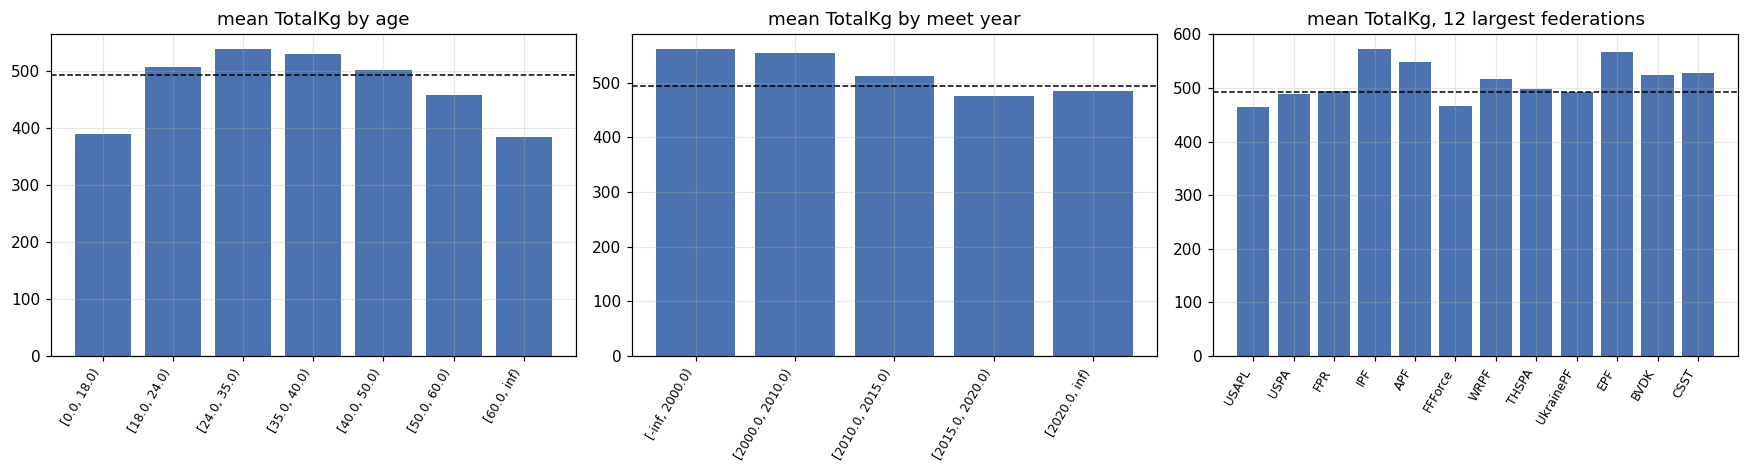

In [6]:
def mean_by(values, order=None):
    table = pd.DataFrame({'k': np.asarray(values).astype(str), 'y': y}).groupby('k')['y'].agg(['size', 'mean'])
    return table if order is None else table.reindex([o for o in order if o in table.index])


age_cut = pd.cut(train['Age'], [0, 18, 24, 35, 40, 50, 60, np.inf], right=False)
year_cut = pd.cut(train['MeetYear'], [-np.inf, 2000, 2010, 2015, 2020, np.inf], right=False)
largest_feds = train['Federation'].value_counts().head(12).index.tolist()
panels = [('mean TotalKg by age', mean_by(age_cut.astype(str), [str(c) for c in age_cut.cat.categories])),
          ('mean TotalKg by meet year', mean_by(year_cut.astype(str), [str(c) for c in year_cut.cat.categories])),
          ('mean TotalKg, 12 largest federations', mean_by(train['Federation'], largest_feds))]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
for ax, (title, table) in zip(axes, panels):
    ax.bar(range(len(table)), table['mean'], color='#4c72b0')
    ax.set_xticks(range(len(table)))
    ax.set_xticklabels(table.index.tolist(), rotation=60, ha='right', fontsize=8)
    ax.axhline(y.mean(), color='black', ls='--', lw=1)
    ax.set_title(presentation_label(title))
plt.tight_layout()
plt.show()

## 5. Précision de saisie

En regardant les valeurs de près, on remarque deux choses :

- beaucoup d'âges finissent par **.5** : seule l'année de naissance est connue ;
- le poids est noté tantôt en entier, tantôt en .5, tantôt avec une ou deux décimales, selon les habitudes de pesée de la fédération.

Un arbre a du mal à retrouver ce genre de motif avec des seuils, donc on en fera des variables (notebook 02). Sur les résidus d'un premier modèle, l'écart entre âges entiers et âges en .5 atteint 24.5 kg à l'USAPL.

In [7]:
def safe_mean(values):
    return float(np.mean(values)) if len(values) else np.nan


age_half = ((train['Age'] * 2).round() % 2).astype(int).to_numpy()      # 1 = âge en x.5 (année de naissance seule connue)
bw = train['BodyweightKg']
is_int = np.isclose(bw, bw.round())
is_1dec = np.isclose(bw * 10, (bw * 10).round())
is_half = is_1dec & ~is_int & np.isclose((bw * 10).round() % 10, 5)
bw_precision = np.select([is_int, is_half, is_1dec], ['Entier', 'x.5', 'Autre décimale'], default='Deux décimales')
precision_rows = []
for fed in ['(ensemble)'] + train['Federation'].value_counts().head(8).index.tolist():
    m = np.ones(n_train, dtype=bool) if fed == '(ensemble)' else (train['Federation'] == fed).to_numpy()
    precision_rows.append({'Fédération': fed, 'effectif': int(m.sum()), 'Part des âges x.5': age_half[m].mean(),
                           'Total moyen : âge entier': safe_mean(y[m & (age_half == 0)]),
                           'Total moyen : âge x.5': safe_mean(y[m & (age_half == 1)]),
                           'Part des poids à deux décimales': float((bw_precision[m] == 'Deux décimales').mean())})
display(pd.DataFrame(precision_rows).set_index('Fédération').round(3))
display(pd.DataFrame({'effectif': pd.Series(bw_precision).value_counts(),
                      'Total moyen': pd.Series(y).groupby(bw_precision).mean()}).round(1))

,effectif,Part des âges x.5,Total moyen : âge entier,Total moyen : âge x.5,Part des poids à deux décimales
Fédération,,,,,
(ensemble),105000,0.482,500.889,484.537,0.296
USAPL,19570,0.791,498.433,455.449,0.261
USPA,11422,0.000,489.001,528.415,0.110
FPR,7933,0.932,553.563,491.080,0.358
IPF,2150,0.729,581.041,568.582,0.457
APF,2106,0.070,545.877,592.045,0.235
FFForce,2009,0.640,447.897,476.176,0.457
WRPF,1823,0.010,516.112,536.944,0.049
THSPA,1818,0.680,495.239,499.920,0.891


,effectif,Total moyen
Autre décimale,52411,492.2
Deux décimales,31085,489.1
Entier,13070,504.6
x.5,8434,494.1


À l'USAPL, 79 % des âges sont en .5, avec un total moyen de 455 kg contre 498 kg pour les âges entiers. À la FPR : 491 contre 554 kg. L'USPA ne note presque jamais d'âge en .5 ; la THSPA garde deux décimales de poids dans 89 % des cas. Ces habitudes de saisie renseignent donc indirectement sur le type de compétition.

## 6. Lignes « jumelles »

Environ 1 % des lignes d'apprentissage ont une autre ligne identique sur les 16 variables. Dans trois cas sur quatre, le total est identique aussi : le même résultat est inscrit dans plusieurs divisions. Le test contient aussi des lignes qui ont une jumelle dans l'apprentissage.

On s'en sert dans le notebook 04 pour rapprocher la prédiction du total connu (gain d'environ 0.2 kg au score public). La clé `core` est moins stricte : âge, poids, année, sexe, fédération, pays et État de compétition, pays et État de résidence.

In [8]:
def matching_record_summary():
    core = ['Age', 'BodyweightKg', 'MeetYear', 'Sex', 'Federation', 'MeetCountry', 'MeetState', 'Country', 'State']
    exact_tr = pd.util.hash_pandas_object(train[RAW_FEATURES], index=False).to_numpy()
    core_tr = pd.util.hash_pandas_object(train[core], index=False).to_numpy()
    exact_te = pd.util.hash_pandas_object(test[RAW_FEATURES], index=False).to_numpy()
    core_te = pd.util.hash_pandas_object(test[core], index=False).to_numpy()
    n_exact = pd.Series(exact_tr).map(pd.Series(exact_tr).value_counts()).to_numpy() - 1    # Sans la ligne elle-même
    n_core = pd.Series(core_tr).map(pd.Series(core_tr).value_counts()).to_numpy() - 1
    level = np.select([n_exact > 0, n_core > 0], ['exact', 'core'], default='none')
    same_total = pd.DataFrame({'k': exact_tr, 'y': y}).duplicated(keep=False).to_numpy()  # Même clé et même résultat sur une autre ligne
    test_exact = np.isin(exact_te, exact_tr)
    test_core = ~test_exact & np.isin(core_te, core_tr)
    display(pd.DataFrame([
        ('Train : jumeau exact sur les 16 variables', int((level == 'exact').sum())),
        ('Train : jumeau core sur les 9 variables seulement', int((level == 'core').sum())),
        ('Part des jumeaux exacts ayant le même TotalKg', f"{same_total[level == 'exact'].mean():.1%}"),
        ('Test : jumeau exact présent dans le train', int(test_exact.sum())),
        ('Test : jumeau core seulement dans le train', int(test_core.sum())),
    ], columns=['Élément', 'Nombre']).set_index('Élément'))
    example_keys = pd.Series(exact_tr[level == 'exact']).drop_duplicates().head(3).to_numpy()
    example = train[np.isin(exact_tr, example_keys)].assign(key=exact_tr[np.isin(exact_tr, example_keys)])
    display(example.sort_values(['key', TARGET]).drop(columns='key').head(8))


matching_record_summary()

,Nombre
Élément,
Train : jumeau exact sur les 16 variables,1109
Train : jumeau core sur les 9 variables seulement,100
Part des jumeaux exacts ayant le même TotalKg,73.4%
Test : jumeau exact présent dans le train,465
Test : jumeau core seulement dans le train,54


,id,Age,BodyweightKg,MeetYear,Sex,Equipment,AgeClass,BirthYearClass,WeightClassKg,Tested,Country,State,Federation,ParentFederation,MeetCountry,MeetState,Sanctioned,TotalKg
88,74580,41.0,131.20,2022,M,Single-ply,40-44,40-49,120+,Yes,USA,MD,AMP,IPF,USA,FL,Yes,810.0
83268,97685,41.0,131.20,2022,M,Single-ply,40-44,40-49,120+,Yes,USA,MD,AMP,IPF,USA,FL,Yes,810.0
259,11375,61.5,53.20,2022,F,Raw,60-64,60-69,56,Yes,USA,TX,USAPL,Unknown,USA,TX,Yes,237.5
64000,10468,61.5,53.20,2022,F,Raw,60-64,60-69,56,Yes,USA,TX,USAPL,Unknown,USA,TX,Yes,237.5
149,67682,19.5,108.15,2026,M,Raw,20-23,19-23,110,Yes,USA,NY,USAPL,Unknown,USA,NY,Yes,760.0
80826,44782,19.5,108.15,2026,M,Raw,20-23,19-23,110,Yes,USA,NY,USAPL,Unknown,USA,NY,Yes,760.0


## 7. Qualité des données

Trois vérifications :

- **validation adversariale** : un classifieur essaie de distinguer apprentissage et test ; une AUC proche de 0.5 veut dire qu'il n'y arrive pas ;
- **ordre des id** : deux lignes voisines viennent-elles plus souvent de la même compétition ?
- **totaux suspects** : totaux très faibles par rapport au poids, souvent une compétition ratée ou incomplète.

In [9]:
from scipy.stats import spearmanr
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score

# 1) Validation adversariale : distinguer train et test
encoded = both_raw.copy()
for c in CAT:
    encoded[c] = encoded[c].astype('category').cat.codes
is_test = np.r_[np.zeros(n_train), np.ones(len(test))]
adversarial_auc = cross_val_score(HistGradientBoostingClassifier(max_iter=200, random_state=SEED), encoded, is_test,
                                  cv=StratifiedKFold(3, shuffle=True, random_state=SEED), scoring='roc_auc').mean()

# 2) Vérifier si les id voisins partagent plus souvent la même compétition
ids_all = pd.concat([train['id'], test['id']], ignore_index=True).to_numpy()
order = np.argsort(ids_all)
perm = np.random.default_rng(0).permutation(len(ids_all))
meet_key = (both_raw['Federation'] + '|' + both_raw['MeetYear'].astype(str) + '|' + both_raw['MeetCountry']
            + '|' + both_raw['MeetState']).to_numpy()
id_rows = []
for name, values in {'Même compétition': meet_key, 'Même fédération': both_raw['Federation'].to_numpy(),
                     'Même année de compétition': both_raw['MeetYear'].to_numpy(), 'Même pays': both_raw['Country'].to_numpy()}.items():
    by_id = float((values[order][1:] == values[order][:-1]).mean())
    shuffled = float((values[perm][1:] == values[perm][:-1]).mean())
    id_rows.append({'Lignes voisines': name, 'Tri par id': by_id, 'Ordre aléatoire': shuffled, 'Rapport': by_id / max(shuffled, 1e-12)})
display(pd.DataFrame(id_rows).set_index('Lignes voisines').round(4))
display(pd.DataFrame([
    ('AUC train/test (0.5 : peu de décalage détectable)', f'{adversarial_auc:.4f}'),
    ('Corrélation Spearman id / TotalKg', f"{float(spearmanr(train['id'], y)[0]):+.4f}"),
    ('Corrélation Spearman id / année (train+test)', f"{float(spearmanr(ids_all, both_raw['MeetYear'])[0]):+.4f}"),
    ('Étendue des id : train / test', f"{train['id'].min()}–{train['id'].max()} / {test['id'].min()}–{test['id'].max()}"),
], columns=['Contrôle', 'Résultat']).set_index('Contrôle'))

# 3) Résultats suspects selon les cibles du train ; essai de suppression dans 05
ratio = y / train['BodyweightKg'].to_numpy(dtype='float64')
suspicious = (np.where(train['Sex'].to_numpy() == 'M', ratio < 2.5, ratio < 1.8)
              | (train['Age'].to_numpy(dtype='float64') < 5))
print(f'Lignes suspectes (total < 2.5 × poids chez les hommes, < 1.8 chez les femmes, ou âge < 5) : {int(suspicious.sum())} ({suspicious.mean():.2%})')
display(train.loc[suspicious, ['Age', 'BodyweightKg', 'Sex', 'Equipment', 'Federation', 'MeetYear', TARGET]].head(8))

,Tri par id,Ordre aléatoire,Rapport
Lignes voisines,,,
Même compétition,0.0004,0.0004,0.9683
Même fédération,0.0579,0.0582,0.9951
Même année de compétition,0.0589,0.0579,1.0181
Même pays,0.2289,0.2309,0.9914


,Résultat
Contrôle,
AUC train/test (0.5 : peu de décalage détectable),0.5017
Corrélation Spearman id / TotalKg,-0.0031
Corrélation Spearman id / année (train+test),+0.0021
Étendue des id : train / test,1–149999 / 0–149993


Lignes suspectes (total < 2.5 × poids chez les hommes, < 1.8 chez les femmes, ou âge < 5) : 265 (0.25%)


,Age,BodyweightKg,Sex,Equipment,Federation,MeetYear,TotalKg
758,15.0,97.40,F,Raw,RAW-CAN,2013,155.00
844,12.5,91.60,M,Raw,USAPL,2018,222.50
1242,38.5,130.40,F,Raw,USAPL,2015,186.00
1667,12.0,59.29,M,Raw,RAW,2022,140.00
1814,3.5,75.00,M,Single-ply,USPF,1981,433.18
1835,77.0,85.80,M,Wraps,APF,2019,162.50
3180,13.5,80.29,F,Single-ply,THSWPA,2016,142.88
3214,16.5,139.10,F,Raw,USAPL,2021,225.00


L'AUC adversariale vaut 0.502 : apprentissage et test se ressemblent.

Après tri par id, deux lignes voisines ne partagent pas plus souvent la même compétition, fédération, année ou pays qu'avec un ordre aléatoire (rapport de 0.97 à 1.02). La corrélation entre id et total est de −0.003. L'id n'est donc pas utilisé comme variable.

Les 265 lignes suspectes (0.25 %) sont gardées : les retirer dégrade le score (notebook 05).

## 8. Cinq plis fixes

Les plis viennent de `KFold(5, shuffle=True, random_state=42)`. Toutes les variantes sont comparées sur les mêmes lignes de validation. L'ensemble final ajoute les graines 7 et 2024, qui ont chacune leur propre découpage.

Dans chaque pli, 10 % de la partie d'apprentissage sont mis de côté pour l'early stopping, et le pli de validation ne sert qu'au score. Nos deux premières versions (v1, v2) arrêtaient l'entraînement directement sur le pli de validation : leur score local était trop optimiste, environ 0.5 kg sous le score public pour v2, contre 0.13 à 0.26 kg pour les versions qui ont suivi ce changement (expériences 07 à 10).

In [10]:
display(pd.DataFrame({'Lignes de validation': np.bincount(FOLD_IDS)[1:],
                      'Moyenne TotalKg': [y[FOLD_IDS == k].mean() for k in range(1, N_FOLDS + 1)],
                      'Écart-type TotalKg': [y[FOLD_IDS == k].std() for k in range(1, N_FOLDS + 1)]},
                     index=pd.Index(range(1, N_FOLDS + 1), name='fold')).round(2))

,Lignes de validation,Moyenne TotalKg,Écart-type TotalKg
fold,,,
1,21000,494.81,171.62
2,21000,492.44,172.32
3,21000,492.77,170.85
4,21000,494.43,170.58
5,21000,490.61,171.57
